# Деревья решений и оценка качества моделей



Дерево решений — это алгоритм машинного обучения, используемый для задач классификации и регрессии. Он представляет собой древовидную структуру, где каждый внутренний узел соответствует проверке одного признака (например, возраст > 18), каждая ветвь — исходу этой проверки, а каждый листовой узел — конечному классу (решению).

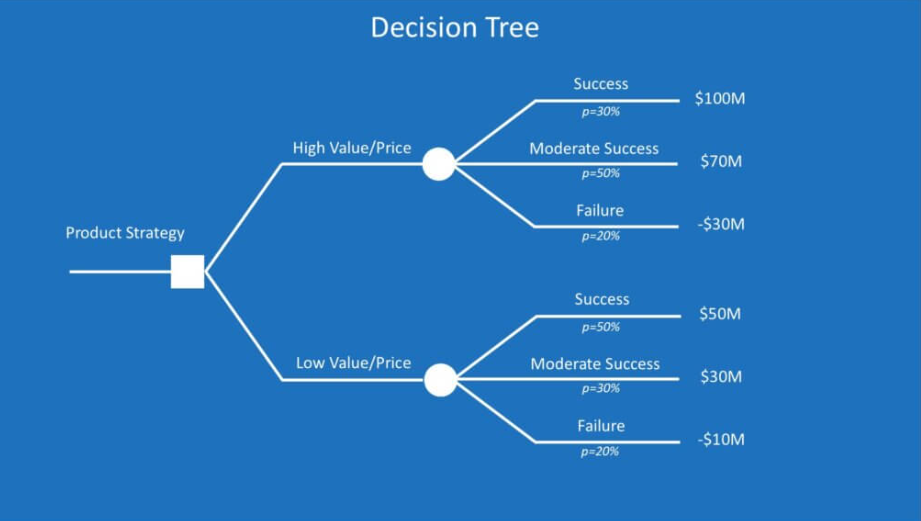

**Практикум по классификации и регрессии**

В этой работе мы разберём две задачи, которые отличаются типом целевой переменной. В первой нужно оценить, согласится ли клиент банка открыть срочный вклад. Во второй — предсказать энергетическую нагрузку здания по его геометрическим характеристикам.

Обе задачи решим с помощью деревьев решений. Затем проверим, что именно говорят метрики, как выглядит ошибка модели и почему высокий результат сам по себе ещё не означает, что модель пригодна для реального применения.

**Что понадобится:** Python, pandas, matplotlib, seaborn и scikit-learn. Данные загружаются из репозитория UCI; для этого ноутбука используется пакет `ucimlrepo`.

## План занятия

- Кратко изучить структуру двух реальных наборов данных.
- Обучить дерево решений для бинарной классификации и разобрать матрицу ошибок, precision, recall и F1.
- Обучить дерево регрессии и оценить ошибки с помощью MAE, MSE и RMSE.
- Сравнить модели с простыми базовыми прогнозами и обсудить ограничения результатов.

Здесь намеренно используются два разных прикладных сюжета. Это помогает увидеть, что алгоритм может быть одним и тем же, а способ оценки его работы зависит от задачи.

## Подготовка окружения

Если библиотек не хватает, установите их в отдельной ячейке:

```python
%pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn
```

При запуске в Google Colab или Jupyter с уже установленными библиотеками повторная установка обычно не требуется.

In [ ]:
%pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42


# Часть I. Классификация: откроет ли клиент срочный вклад?

## Постановка задачи

Банк проводит телефонные маркетинговые кампании и хочет оценить вероятность того, что клиент оформит срочный вклад. Целевая переменная `y` принимает два значения: `yes` и `no`.

Это задача **бинарной классификации**. Важно не только посчитать долю правильных ответов, но и понять, какие ошибки совершает модель. Например, если модель рекомендует связаться с клиентом, который в итоге не откроет вклад, банк тратит ресурсы на безрезультатный контакт. Если же модель не выделяет потенциального клиента, может быть упущена возможность продажи.

Источник данных: Moro, Rita и Cortez, *Bank Marketing*, UCI Machine Learning Repository. В наборе `bank-full` 45 211 наблюдений и 17 признаков. В исходном описании отдельно отмечено, что длительность разговора (`duration`) сильно связана с целевой переменной, но заранее неизвестна до завершения звонка. Поэтому ниже мы исключим её из признаков: иначе учебный эксперимент может переоценить качество модели для сценария, когда решение нужно принять **до звонка**.

Источник: https://archive.ics.uci.edu/dataset/222/bank+marketing

In [ ]:
bank = fetch_ucirepo(id=222)
X_bank_raw = bank.data.features.copy()
y_bank_raw = bank.data.targets.copy()

print("Размер таблицы признаков:", X_bank_raw.shape)
print("Целевая переменная:")
display(y_bank_raw.head())
display(X_bank_raw.head())

Размер таблицы признаков: (45211, 16)
Целевая переменная:


,y
0,no
1,no
2,no
3,no
4,no


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN


### Разберёмся с полями

В наборе есть числовые признаки, например возраст и средний годовой баланс, и категориальные признаки: профессия, семейное положение, образование, тип контакта и результат предыдущей кампании.

Некоторые поля описывают сведения о клиенте, другие — историю маркетинговых контактов. Это не одно и то же: наличие связи с целевой переменной ещё не означает, что признак будет доступен в момент принятия решения.

In [ ]:
# В разных версиях пакета цель может быть DataFrame из одного столбца.
y_bank = y_bank_raw.iloc[:, 0] if isinstance(y_bank_raw, pd.DataFrame) else y_bank_raw
y_bank = y_bank.astype(str).str.strip().str.lower()

X_bank = X_bank_raw.copy()

# Длительность текущего звонка известна только после звонка.
# Исключаем её, чтобы не использовать информацию из будущего.
if "duration" in X_bank.columns:
    X_bank = X_bank.drop(columns=["duration"])

print("Число наблюдений:", len(X_bank))
print("Число признаков после исключения duration:", X_bank.shape[1])
print("Доля положительного класса (yes):", round((y_bank == "yes").mean(), 3))
print("Типы признаков:")
display(X_bank.dtypes.astype(str).value_counts().rename_axis("Тип").to_frame("Количество"))

Число наблюдений: 45211
Число признаков после исключения duration: 15
Доля положительного класса (yes): 0.117
Типы признаков:


,Количество
Тип,
object,9
int64,6


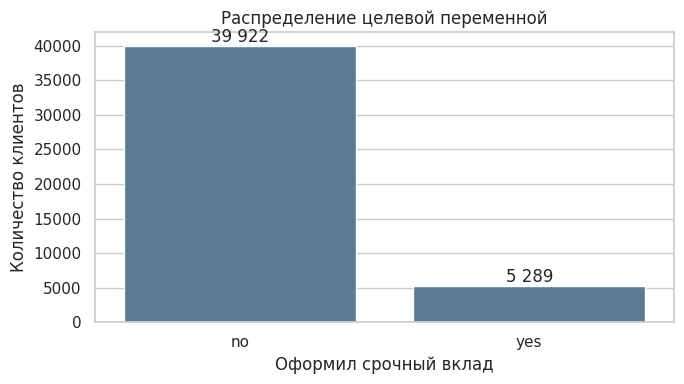

,Доля
y,
no,88.3%
yes,11.7%


In [ ]:
class_counts = y_bank.value_counts().reindex(["no", "yes"])

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax, color="#547A9E")
ax.set(title="Распределение целевой переменной", xlabel="Оформил срочный вклад", ylabel="Количество клиентов")

for i, v in enumerate(class_counts.values):
    ax.text(i, v, f"{v:,}".replace(",", " "), ha="center", va="bottom")

plt.tight_layout()
plt.show()

display((class_counts / class_counts.sum()).rename("Доля").to_frame().style.format("{:.1%}"))

**Что видно на графике?** В данных классы представлены неравномерно: отказов больше, чем согласий. Поэтому модель, которая почти всегда отвечает `no`, может получить сравнительно высокую accuracy, но быть мало полезной для поиска клиентов, готовых открыть вклад.

Это повод сравнить дерево не только с другой моделью, но и с простым базовым прогнозом.

## Подготовка признаков и разделение данных

Категориальные значения нельзя напрямую передать обычному дереву scikit-learn в виде строк. Преобразуем их в индикаторные столбцы с помощью `OneHotEncoder`. Преобразования будут собраны в `Pipeline`, чтобы обучаться только на тренировочной части данных.

Тестовая выборка не участвует в подборе параметров и обучении модели. Она нужна для итоговой оценки на данных, которые модель не видела.

In [ ]:
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_bank, y_bank,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_bank
)

cat_cols_b = X_train_b.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols_b = [c for c in X_train_b.columns if c not in cat_cols_b]

preprocess_b = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols_b),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols_b)
    ],
    remainder="drop"
)

print(f"Обучающая выборка: {X_train_b.shape[0]:,} строк")
print(f"Тестовая выборка: {X_test_b.shape[0]:,} строк")
print(f"Числовых признаков: {len(num_cols_b)}; категориальных: {len(cat_cols_b)}")

Обучающая выборка: 33,908 строк
Тестовая выборка: 11,303 строк
Числовых признаков: 6; категориальных: 9


## Обучение дерева и базовой модели

Ограничим глубину дерева значением 5. Это не универсально оптимальный параметр, а разумная отправная точка для разбора структуры модели. В практической задаче глубину выбирают на отдельной валидационной выборке или с помощью кросс-валидации.

Базовая модель `DummyClassifier` всегда выбирает наиболее частый класс. Если дерево не превосходит её по метрикам, усложнение модели не принесло ожидаемой пользы.

In [ ]:
tree_clf = Pipeline(steps=[
    ("preprocess", preprocess_b),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=30,
        class_weight=None,
        random_state=RANDOM_STATE
    ))
])

baseline_clf = DummyClassifier(strategy="most_frequent")

tree_clf.fit(X_train_b, y_train_b)
baseline_clf.fit(X_train_b, y_train_b)

pred_b = tree_clf.predict(X_test_b)
pred_base_b = baseline_clf.predict(X_test_b)

def classification_metrics(y_true, y_pred, name):
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (yes)": precision_score(y_true, y_pred, pos_label="yes", zero_division=0),
        "Recall (yes)": recall_score(y_true, y_pred, pos_label="yes", zero_division=0),
        "F1 (yes)": f1_score(y_true, y_pred, pos_label="yes", zero_division=0)
    }

classification_results = pd.DataFrame([
    classification_metrics(y_test_b, pred_base_b, "Базовая: частый класс"),
    classification_metrics(y_test_b, pred_b, "Дерево решений")
]).set_index("Модель")

display(classification_results.style.format("{:.3f}"))

,Accuracy,Precision (yes),Recall (yes),F1 (yes)
Модель,,,,
Базовая: частый класс,0.883,0.000,0.000,0.000
Дерево решений,0.895,0.662,0.203,0.310


## Матрица ошибок

Матрица ошибок сопоставляет истинный класс с предсказанным. Здесь положительный класс — `yes`, то есть клиент оформил вклад.

- **TP**: клиент оформил вклад, и модель это предсказала.
- **TN**: клиент не оформил вклад, и модель это предсказала.
- **FP**: модель ожидала оформление, но клиент отказался.
- **FN**: клиент оформил вклад, но модель не выделила его.

Ни одна из этих ошибок не является «лучшей» или «худшей» сама по себе: последствия зависят от стоимости контакта, ценности клиента и бизнес-процесса.

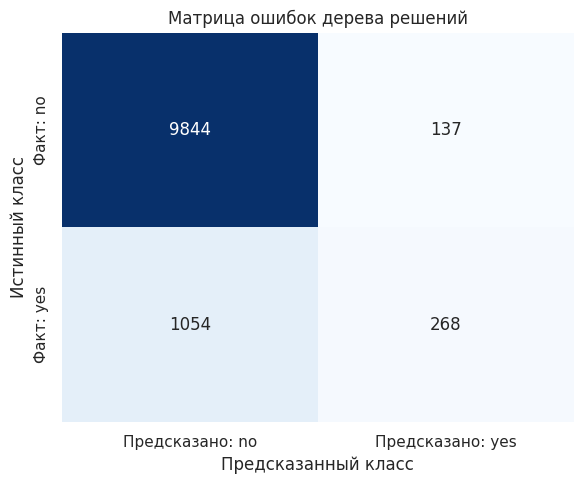

              precision    recall  f1-score   support

          no       0.90      0.99      0.94      9981
         yes       0.66      0.20      0.31      1322

    accuracy                           0.89     11303
   macro avg       0.78      0.59      0.63     11303
weighted avg       0.88      0.89      0.87     11303



In [ ]:
cm = confusion_matrix(y_test_b, pred_b, labels=["no", "yes"])
fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Предсказано: no", "Предсказано: yes"],
    yticklabels=["Факт: no", "Факт: yes"], ax=ax
)

ax.set_title("Матрица ошибок дерева решений")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
plt.tight_layout()
plt.show()

print(classification_report(y_test_b, pred_b, labels=["no", "yes"], zero_division=0))

### Метрики классификации:

объяснение на примере банка
Представим, что модель проверила 100 клиентов и получила следующие результаты:

| Фактический результат |	Предсказано «вклад» |	Предсказано «нет вклада» |
|-----------------------|---------------------|--------------------------|
| Вклад оформлен | 15 |	5 |
| Вклад не оформлен |	10 |	70 |

Из этой таблицы можно вычислить все основные метрики.

**Accuracy** — доля верных ответов

$ Accuracy = \frac{15 + 70}{100} = 0.85 = 85\% $

Модель правильно классифицировала 85 клиентов из 100. Но сама по себе эта цифра не показывает, сколько заинтересованных клиентов было пропущено.



---



**Precision** — точность положительных прогнозов (правый столбец)

$ Precision = \frac{15}{15+10} = 0.6 = 60\% $

Из 25 клиентов, которым модель предсказала оформление вклада, действительно оформили его 15. Остальные 10 — ложноположительные прогнозы.



---

**Recall** — полнота обнаружения

$ Recall = \frac{15}{15+5} = 0.75 = 75\% $

Модель нашла 15 из 20 клиентов, которые действительно оформили вклад. Пять потенциальных клиентов остались незамеченными (ложно отрицательные)

---
**F1** — баланс Precision и Recall

$F1 = 2*\frac{0.6 * 0.75}{0.6 * 0.7} = 0.667 = 66.7\%$

F1 позволяет оценить баланс точности и полноты одним числом. Однако она не учитывает напрямую стоимость каждого звонка или упущенной продажи.

---

## Как читать метрики

**Accuracy** — доля правильных ответов среди всех наблюдений. При дисбалансе классов она может скрывать плохое распознавание редкого класса.

**Precision** для класса `yes` показывает, какая доля клиентов, отмеченных моделью как потенциальные покупатели, действительно оформила вклад.

**Recall** показывает, какую долю всех клиентов, оформивших вклад, модель смогла найти.

**F1** — гармоническое среднее precision и recall. Эта метрика полезна, когда важно учитывать обе стороны качества, но она не заменяет анализа стоимости ошибок.

Для маркетинговой кампании высокая полнота может быть важна, если банк хочет не пропустить потенциальных клиентов. Высокая точность может быть важнее, если число доступных звонков ограничено и каждый контакт дорог. Решение о метрике должно следовать из цели, а не наоборот.

## Что дерево использует для принятия решений?

Посмотрим на несколько верхних уровней дерева. После кодирования категориальных полей число признаков увеличивается, поэтому подписи могут быть длинными. Ограничим визуализацию глубиной 3 — это только фрагмент полной модели, удобный для обсуждения.

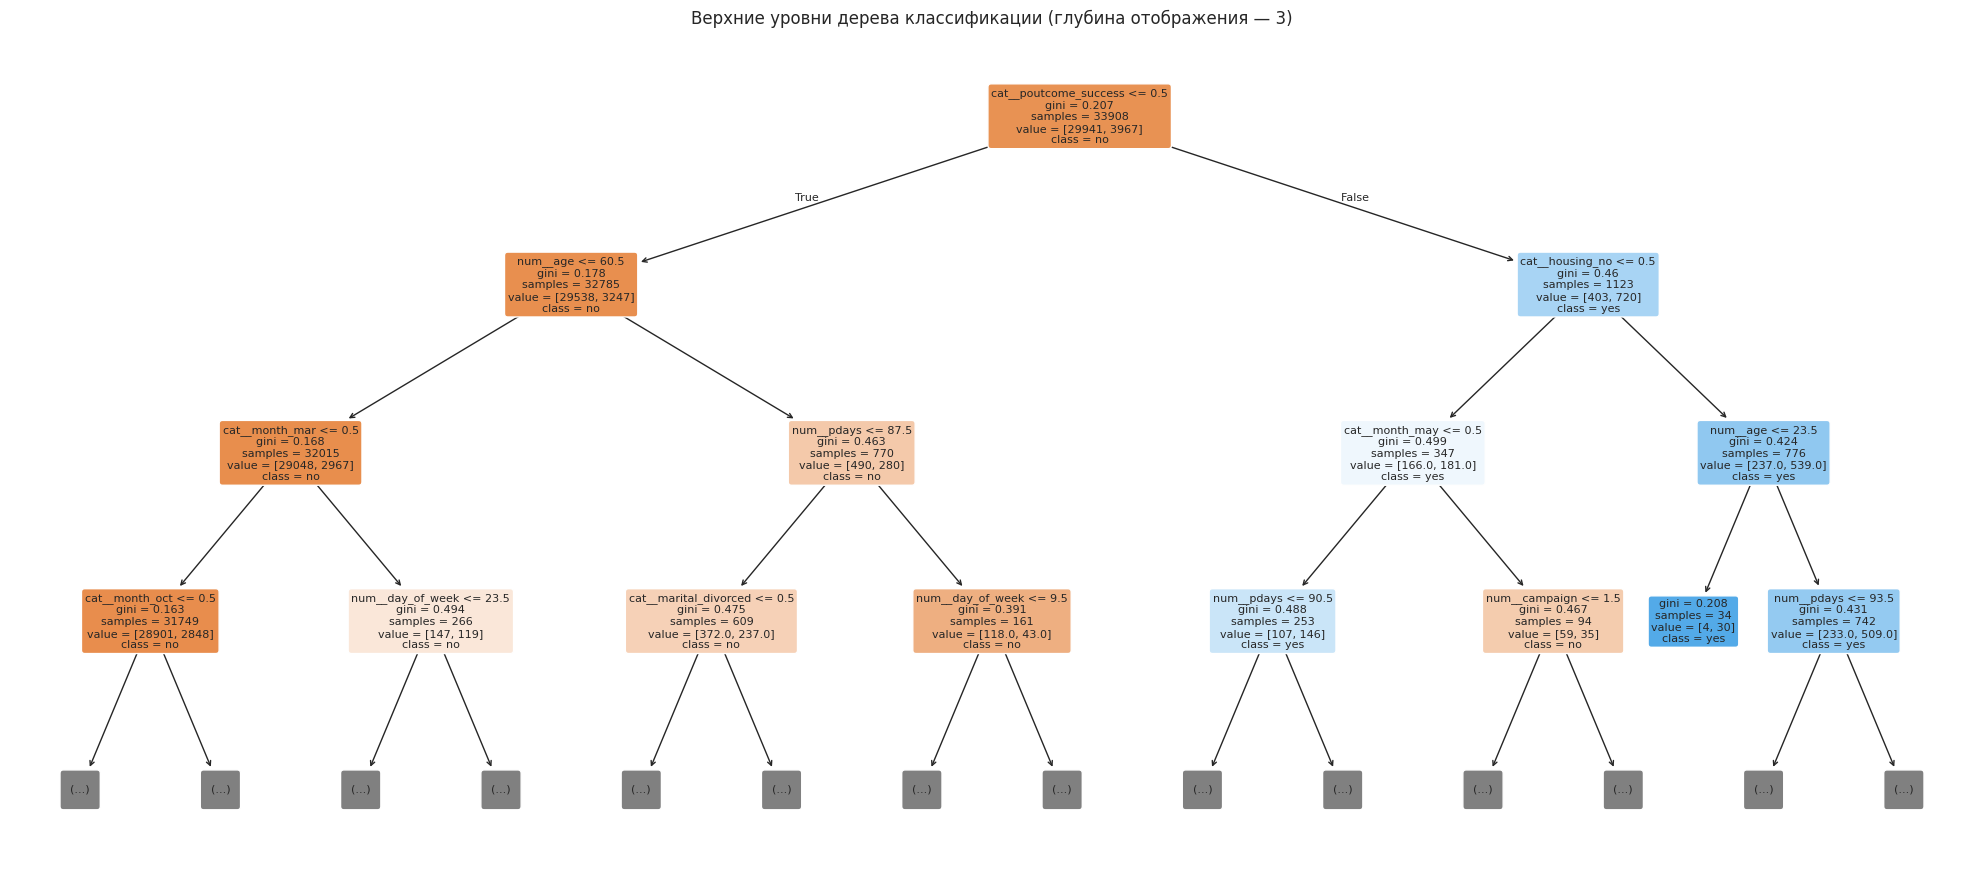

In [ ]:
preprocessor_fitted = tree_clf.named_steps["preprocess"]
feature_names_b = preprocessor_fitted.get_feature_names_out()
tree_model_b = tree_clf.named_steps["model"]

fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(
    tree_model_b,
    feature_names=feature_names_b,
    class_names=["no", "yes"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
    ax=ax
)
ax.set_title("Верхние уровни дерева классификации (глубина отображения — 3)")
plt.tight_layout()
plt.show()

## Как работает дерево решений?
Алгоритм решает, какой признак и какое пороговое значение лучше всего разделяет выборку на каждом шаге. Этот процесс называется рекурсивным бинарным разбиением.

1. Начинаем с корневого узла, который содержит все обучающие данные.
2. Для каждого признака алгоритм перебирает все возможные пороговые значения.
3. Для каждого разбиения он вычисляет, насколько хорошо оно разделяет данные на классы. Мера качества разбиения называется критерием разделения.
4. Выбирается признак и порог, которые дают наилучшее разделение (например, максимизируют прирост информации).
5. Данные разделяются на две части, и процесс повторяется рекурсивно для каждой из получившихся частей (дочерних узлов).
6. Процесс останавливается, когда выполняется одно из условий остановки (например, достигнута максимальная глубина дерева, в узле осталось слишком мало образцов или все образцы в узле принадлежат одному классу).

### Как параметры меняют дерево:

**max_depth** — максимальная глубина
При глубине 1 дерево может принять решение по одному условию. При глубине 5 оно способно учитывать более сложные сочетания признаков. Увеличение глубины часто улучшает качество на обучающей выборке, но иногда ухудшает результат на новых данных из-за переобучения.

**min_samples_leaf** — минимум объектов в листе
Значение 30 означает, что каждый конечный узел должен содержать не менее 30 обучающих наблюдений. Это ограничивает слишком детальные правила. Увеличение параметра обычно делает дерево более устойчивым, но чрезмерное ограничение способно привести к недообучению.

**class_weight** — веса классов
При значении None классы не получают дополнительных весов. Значение "balanced" автоматически увеличивает вес менее распространённого класса. Это может помочь обнаруживать больше клиентов, готовых открыть вклад, но одновременно увеличить количество ложноположительных прогнозов.

**criterion** — критерий выбора разбиения
Например, gini оценивает неоднородность классов в узле. Дерево выбирает условия, которые уменьшают эту неоднородность. entropy использует другой критерий, основанный на энтропии. Ни один из них не обязан давать лучший результат во всех задачах.

### Критерии разбиения: индекс Джини и энтропия

### Индекс Джини
Индекс Джини показывает, насколько неоднородны классы в узле дерева. Если в узле находятся объекты только одного класса, неопределённость равна нулю. Чем сильнее смешаны классы, тем выше значение индекса.

Формула:

$Gini = 1 - \sum_{i=1}^{K}p_i^2$

Здесь K — количество классов, а $p_i$ — доля объектов класса i в узле.


---


Для бинарной классификации:

$Gini = 1 - p^2 - (1 - p)^2 = 2p(1-p)$

Например, если в узле 80 объектов класса A и 20 объектов класса B:

$Gini = 1 - 0.8^2 - 0.2^2 = 0.32$

Если все 100 объектов относятся к одному классу, индекс Джини равен нулю.

### Энтропия
Энтропия тоже измеряет неоднородность классов, но использует логарифм вероятности каждого класса:

$H = -\sum_{i=1}^{K}p_ilog_2(p_i)$

---

Для бинарной классификации:

$H = -plog_2(p) - (1 - p)log_2(1-p)$

При p=0.8 энтропия составляет примерно 0.722 бита. При одинаковом количестве объектов двух классов она достигает максимума — 1 бит.

В формулах принято считать $0log_2(0)=0$.

**Важно:** индекс Джини и энтропия — разные способы измерить неоднородность, поэтому их численные значения напрямую сравнивать нельзя. Для выбора разбиения дерево оценивает, насколько уменьшается неоднородность после разделения узла.







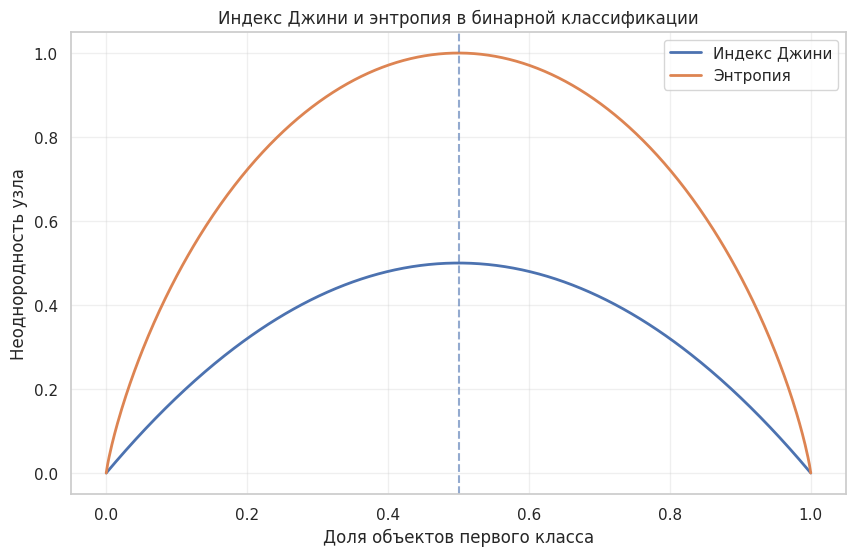

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Доля объектов первого класса
p = np.linspace(0, 1, 501)

# Индекс Джини
gini = 2 * p * (1 - p)

# Энтропия: отдельно обрабатываем крайние точки,
# чтобы избежать log2(0)
entropy = np.zeros_like(p)
mask = (p > 0) & (p < 1)

entropy[mask] = (
    -p[mask] * np.log2(p[mask])
    -(1 - p[mask]) * np.log2(1 - p[mask])
)

plt.figure(figsize=(10, 6))
plt.plot(p, gini, label="Индекс Джини", linewidth=2)
plt.plot(p, entropy, label="Энтропия", linewidth=2)

plt.axvline(0.5, linestyle="--", alpha=0.6)
plt.xlabel("Доля объектов первого класса")
plt.ylabel("Неоднородность узла")
plt.title("Индекс Джини и энтропия в бинарной классификации")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Графики: как меняются Джини и энтропия
На графике по горизонтали будет доля объектов одного класса p, а по вертикали — значение критерия. При p=0 и p=1 узел полностью чистый. При p=0.5 классы представлены поровну и неопределённость максимальна.

### Как дерево выбирает разбиение
Дерево не просто ищет узел с минимальным значением критерия. Оно сравнивает возможные разбиения и выбирает то, которое сильнее уменьшает неоднородность.
Для Джини:

$\Delta Gini = \mathrm{Gini}_{parent} - (\frac{N_L}{N}Gini_L + \frac{N_R}{N}Gini_R)$

Для энтропии аналогично:

$IG = \mathrm{H}_{parent} - (\frac{N_L}{N}H_L + \frac{N_R}{N}H_R)$

Здесь N — число объектов в родительском узле, N_L и N_R — количество объектов в дочерних узлах. Веса учитывают, что дочерние узлы могут быть разного размера.

In [ ]:
import numpy as np

def gini_impurity(y):
    _, counts = np.unique(y, return_counts=True)
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)

def entropy_impurity(y):
    _, counts = np.unique(y, return_counts=True)
    p = counts / counts.sum()
    return -np.sum(p * np.log2(p))

def split_gain(y_parent, y_left, y_right, criterion):
    impurity = {
        "gini": gini_impurity,
        "entropy": entropy_impurity
    }[criterion]

    n = len(y_parent)
    weighted_children = (
        len(y_left) / n * impurity(y_left)
        + len(y_right) / n * impurity(y_right)
    )

    return impurity(y_parent) - weighted_children

# Один и тот же родительский узел: 50 объектов каждого класса
y_parent = np.array([0] * 50 + [1] * 50)

# Разбиение A: дочерние узлы получились достаточно чистыми
y_left_A = np.array([0] * 45 + [1] * 5)
y_right_A = np.array([0] * 5 + [1] * 45)

# Разбиение B: классы разделены хуже
y_left_B = np.array([0] * 30 + [1] * 20)
y_right_B = np.array([0] * 20 + [1] * 30)

for criterion in ["gini", "entropy"]:
    gain_A = split_gain(
        y_parent, y_left_A, y_right_A, criterion
    )
    gain_B = split_gain(
        y_parent, y_left_B, y_right_B, criterion
    )

    print(f"\nКритерий: {criterion}")
    print(f"Прирост для разбиения A: {gain_A:.4f}")
    print(f"Прирост для разбиения B: {gain_B:.4f}")


Критерий: gini
Прирост для разбиения A: 0.3200
Прирост для разбиения B: 0.0200

Критерий: entropy
Прирост для разбиения A: 0.5310
Прирост для разбиения B: 0.0290


Разбиение A даст больший прирост по обоим критериям, поскольку дочерние узлы в нём чище.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_gini = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_leaf=30,
    random_state=42
)

tree_entropy = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5,
    min_samples_leaf=30,
    random_state=42
)

### Что важно:

* gini обычно является быстрым и распространённым вариантом.

* entropy основана на теории информации и использует логарифмы.

* Нет гарантии, что один критерий всегда даст лучшую точность на тестовой выборке.

* Даже при разных критериях итоговые деревья могут оказаться одинаковыми или очень похожими.

* Сравнивать модели нужно на одних и тех же данных, с одинаковыми ограничениями глубины и размера листа.

### Промежуточный вывод по классификации

Дерево превращает набор признаков в последовательность условий. Оно сравнительно легко объясняется: для конкретного наблюдения можно проследить путь от корня до листа. При этом даже понятная структура не гарантирует высокого качества на новых данных.

При интерпретации результата учитывайте три ограничения. Во-первых, классы несбалансированы. Во-вторых, исключение `duration` делает эксперимент ближе к сценарию прогнозирования до звонка, но не устраняет все возможные смещения данных. В-третьих, выбранная глубина не была оптимизирована — здесь она нужна прежде всего для учебного сравнения.

### Вопросы для обсуждения

- Почему accuracy базовой модели может оказаться выше, чем ожидается?
- В какой ситуации банку важнее precision, а в какой — recall?
- Почему `duration` нельзя использовать, если задача — выбрать клиентов до начала звонка?
- Что изменится, если увеличить `max_depth`? Почему более глубокое дерево не обязательно лучше?
- Какие данные о кампании могли бы понадобиться, чтобы проверить качество модели на будущих звонках, а не на случайно отложенной части старой выборки?

# Часть II. Регрессия: энергетическая нагрузка здания

## Постановка задачи

Набор **Energy Efficiency** содержит характеристики геометрии зданий и показатели их энергетической эффективности. В нём восемь признаков: относительная компактность, площадь поверхности, площадь стен и крыши, высота, ориентация, площадь остекления и распределение остекления. Целевые переменные — нагрузка на отопление (`Y1`, Heating Load) и нагрузка на охлаждение (`Y2`, Cooling Load).

В этом разделе будем предсказывать нагрузку на отопление. Это **задача регрессии**, потому что целевая переменная — числовая величина, а не категория.

Набор содержит 768 наблюдений и опубликован в UCI Machine Learning Repository. Это исследовательский набор с расчётными характеристиками зданий, а не поток показаний с реальных счётчиков. При обсуждении результатов не следует автоматически переносить их на любой жилой дом.

Источник: Tsanas и Xifara (2012), UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/242/energy+efficiency

In [ ]:
energy = fetch_ucirepo(id=242)
X_energy = energy.data.features.copy()
y_energy_all = energy.data.targets.copy()

print("Размер матрицы признаков:", X_energy.shape)
print("Целевые переменные:", list(y_energy_all.columns))
display(X_energy.head())
display(y_energy_all.head())

Размер матрицы признаков: (768, 8)
Целевые переменные: ['Y1', 'Y2']


,X1,X2,X3,X4,X5,X6,X7,X8
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0


,Y1,Y2
0,15.55,21.33
1,15.55,21.33
2,15.55,21.33
3,15.55,21.33
4,20.84,28.28


## Первичный анализ

Сначала проверим типы данных, пропуски и распределение целевой переменной. Это не формальность: если в данных есть пропуски, некорректные типы или необычные значения, обучение модели может завершиться ошибкой либо дать вводящий в заблуждение результат.

Пропуски в признаках: 0
Пропуски в целевой переменной: 0


,count,mean,std,min,25%,50%,75%,max
X1,768.0,0.764,0.106,0.62,0.682,0.75,0.830,0.98
X2,768.0,671.708,88.086,514.50,606.375,673.75,741.125,808.50
X3,768.0,318.500,43.626,245.00,294.000,318.50,343.000,416.50
X4,768.0,176.604,45.166,110.25,140.875,183.75,220.500,220.50
X5,768.0,5.250,1.751,3.50,3.500,5.25,7.000,7.00
X6,768.0,3.500,1.119,2.00,2.750,3.50,4.250,5.00
X7,768.0,0.234,0.133,0.00,0.100,0.25,0.400,0.40
X8,768.0,2.812,1.551,0.00,1.750,3.00,4.000,5.00
Heating Load (Y1),768.0,22.307,10.090,6.01,12.992,18.95,31.668,43.10


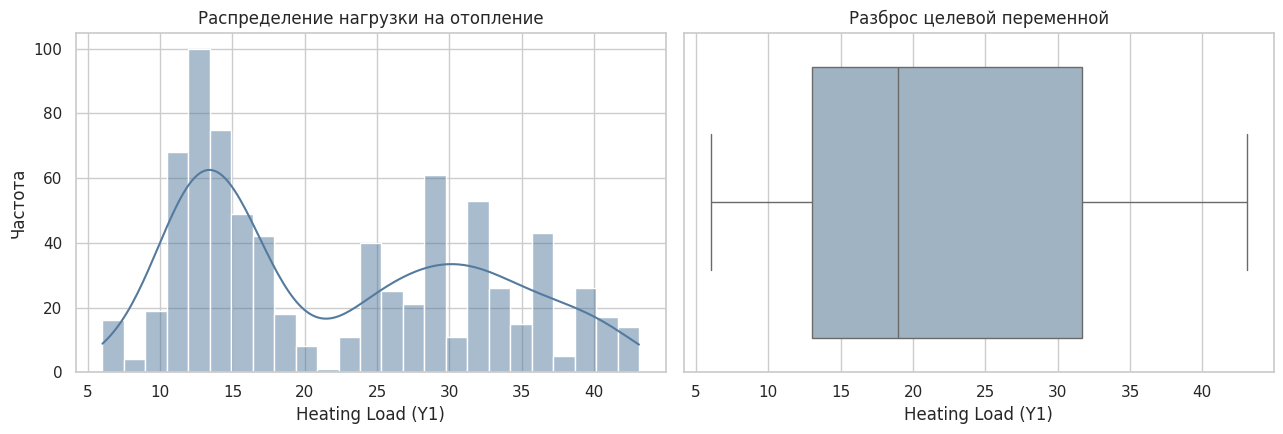

In [ ]:
y_energy = y_energy_all["Y1"].astype(float)
energy_df = X_energy.copy()
energy_df["Heating Load (Y1)"] = y_energy

print("Пропуски в признаках:", int(X_energy.isna().sum().sum()))
print("Пропуски в целевой переменной:", int(y_energy.isna().sum()))
display(energy_df.describe().T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(y_energy, bins=25, kde=True, ax=axes[0], color="#547A9E")
axes[0].set(title="Распределение нагрузки на отопление", xlabel="Heating Load (Y1)", ylabel="Частота")
sns.boxplot(x=y_energy, ax=axes[1], color="#9AB4C8")
axes[1].set(title="Разброс целевой переменной", xlabel="Heating Load (Y1)")
plt.tight_layout()
plt.show()

### Связь отдельных признаков с нагрузкой

Диаграммы рассеяния помогают увидеть возможные зависимости, но сами по себе не доказывают причинно-следственную связь. В частности, некоторые геометрические признаки связаны друг с другом: например, площадь поверхности и площадь крыши могут отражать общие особенности формы здания.

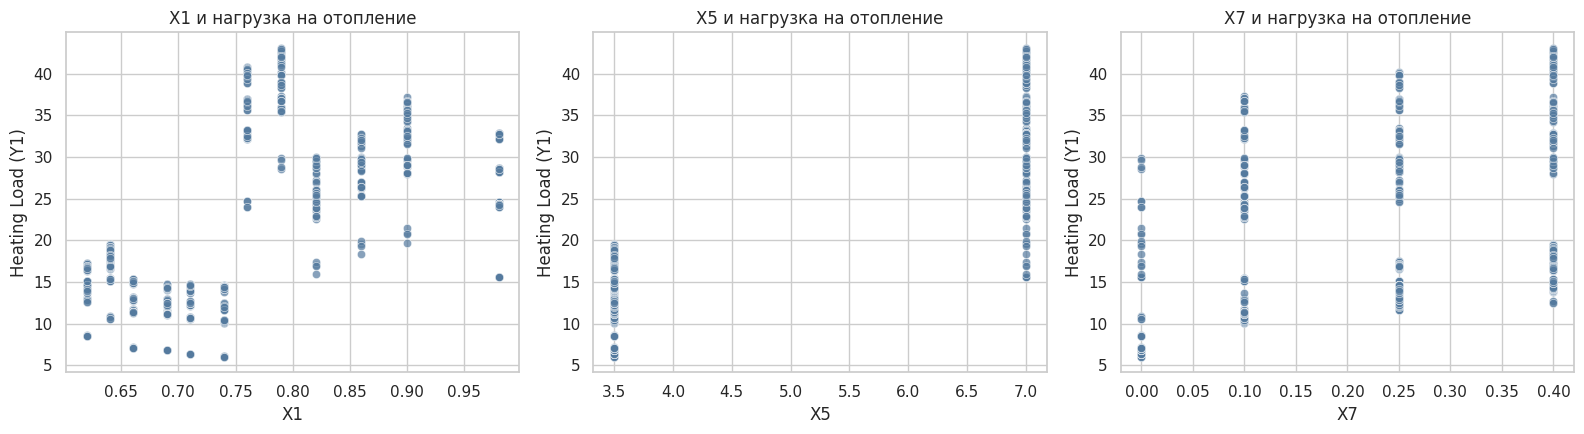

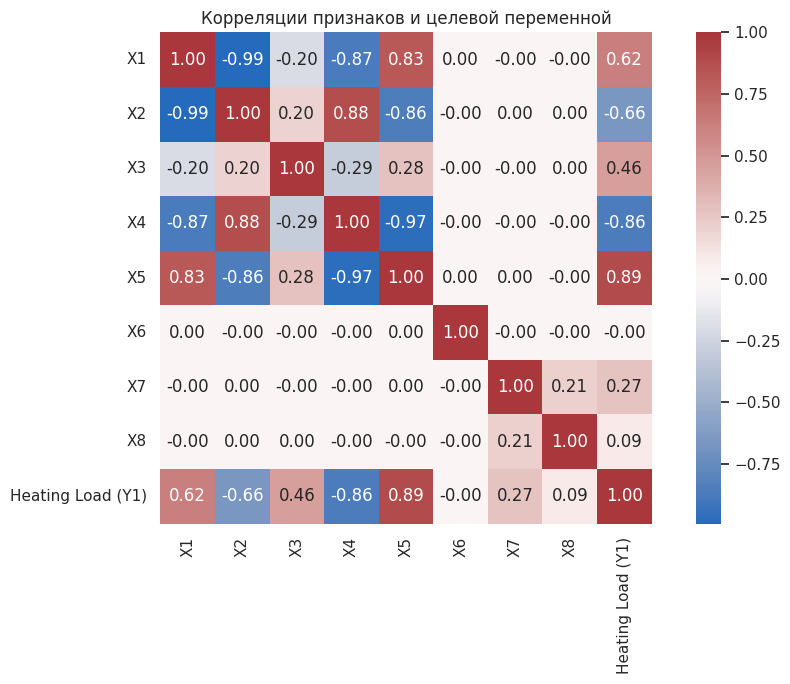

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["X1", "X5", "X7"]):
    sns.scatterplot(data=energy_df, x=col, y="Heating Load (Y1)", alpha=0.7, ax=ax, color="#547A9E")
    ax.set_title(f"{col} и нагрузка на отопление")
    ax.set_xlabel(col)
    ax.set_ylabel("Heating Load (Y1)")
plt.tight_layout()
plt.show()

corr = energy_df.corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", square=True)
plt.title("Корреляции признаков и целевой переменной")
plt.tight_layout()
plt.show()

## Обучение дерева регрессии

Разделим наблюдения на обучающую и тестовую части. Обучим дерево с ограничением глубины и минимального числа объектов в листе. Затем сравним его с `DummyRegressor`, который предсказывает среднее значение целевой переменной из обучающей выборки.

Базовый прогноз нужен, чтобы ответить на практический вопрос: даёт ли модель пользу по сравнению с очень простым решением?

In [ ]:
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_energy, y_energy,
    test_size=0.25,
    random_state=RANDOM_STATE
)

tree_reg = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=8,
    random_state=RANDOM_STATE
)
baseline_reg = DummyRegressor(strategy="mean")

tree_reg.fit(X_train_e, y_train_e)
baseline_reg.fit(X_train_e, y_train_e)

pred_e = tree_reg.predict(X_test_e)
pred_base_e = baseline_reg.predict(X_test_e)

def regression_metrics(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "Модель": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_true, y_pred)
    }

regression_results = pd.DataFrame([
    regression_metrics(y_test_e, pred_base_e, "Базовая: среднее"),
    regression_metrics(y_test_e, pred_e, "Дерево регрессии")
]).set_index("Модель")

display(regression_results.style.format("{:.3f}"))

,MAE,MSE,RMSE,R²
Модель,,,,
Базовая: среднее,9.322,105.784,10.285,-0.006
Дерево регрессии,1.449,4.102,2.025,0.961


### Метрики качества регрессии:

В регрессии модель предсказывает числовое значение: цену квартиры, расход энергии, зарплату, температуру или время доставки. Чтобы понять, насколько хорошо она работает, нужно сравнить реальные значения с предсказаниями модели.
Для этого будем использовать четыре основные метрики:
- MAE — средняя абсолютная ошибка;
- MSE — средняя квадратичная ошибка;
- RMSE — корень из средней квадратичной ошибки;
- \(R^2\) — коэффициент детерминации.

Они оценивают качество с разных сторон. Поэтому важно не просто вывести четыре числа, а понять, что именно означает каждое из них и в каких ситуациях оно полезно.

### Что такое ошибка предсказания

Обозначим:
- $y_i$ — реальное значение для объекта \(i\);
- $\hat{y_i}$ — предсказание модели;
- n — количество объектов;
- $e_i=y_i- \hat{y_i}$ — ошибка предсказания.

Например, модель предсказывает потребление энергии зданием. Реальное значение составляет 120, а модель предсказала 110. Тогда ошибка равна:

$
e_i=y_i-\hat y_i=120-110=10
$

Если модель предсказала 130, ошибка будет -10. Знак показывает направление ошибки: положительная означает недооценку реального значения, отрицательная — переоценку, если определять ошибку как $y_i-\hat y_i$.


Для оценки качества модели часто важно не направление, а величина ошибки. Именно поэтому MAE и MSE используют абсолютные значения или квадраты ошибок.



---



### MAE — средняя абсолютная ошибка
$
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|
$


> Чем меньше MAE, тем в среднем ближе предсказания к реальным значениям.

MAE рассчитывает модуль ошибки для каждого объекта, складывает ошибки и делит сумму на число объектов. Модуль убирает знак, поэтому ошибки переоценки и недооценки не компенсируют друг друга.

Пример. Пусть модель предсказала стоимость четырёх объектов:

|Объект|	Реальное значение|	Предсказание	|Абсолютная ошибка|
|------|-------------------|----------------|-----------------|
|A|	100|	90|	10|
|B|	150|	160|	10|
|C|	200|	180|	20|
|D|	250|	260|	10|

Тогда:

$
MAE=\frac{10+10+20+10}{4}=12.5
$

То есть средняя абсолютная ошибка составляет 12,5 единицы целевой переменной. Если предсказываем цену в тысячах рублей, MAE будет равна 12,5 тысячи рублей.

**Преимущества MAE**
- Легко интерпретировать: ошибка выражена в тех же единицах, что и целевая переменная.
- Одна крупная ошибка не усиливается квадратично, как в MSE.
- Подходит, когда важна средняя величина отклонения в понятных предметных единицах.


**Недостатки MAE**
- Ошибка на 10 единиц и ошибка на 100 единиц учитываются пропорционально их величине, без дополнительного усиления крупных промахов.
- MAE не показывает направление ошибки. Модель может систематически завышать или занижать значения, даже если MAE выглядит приемлемо.

MAE полезна, например, когда заказчик хочет понимать, насколько в среднем ошибается прогноз цены или потребления энергии.



---



### MSE — средняя квадратичная ошибка

MSE — Mean Squared Error

$
MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2
$

> Чем меньше MSE, тем лучше; большие ошибки получают значительно больший вес.

Вместо модуля MSE возводит каждую ошибку в квадрат. Благодаря этому отрицательные и положительные ошибки не компенсируют друг друга, а большие отклонения становятся особенно заметными.

Рассмотрим два набора ошибок для пяти объектов:
- Модель A: 1, 2, 2, 3, 2
- Модель B: 0, 0, 0, 0, 10

Для первой модели:

$
MAE_A=\frac{1+2+2+3+2}{5}=2
$

$
MSE_A=\frac{1+4+4+9+4}{5}=4.4
$

Для второй:

$
MAE_B=\frac{0+0+0+0+10}{5}=2
$

$
MSE_B=\frac{0+0+0+0+100}{5}=20
$


> У моделей одинаковый MAE, но MSE второй модели значительно выше. Это происходит из-за одного крупного промаха

### Почему квадрат усиливает крупные ошибки
Посмотри, как растёт вклад ошибки при переходе от абсолютной величины к квадрату.

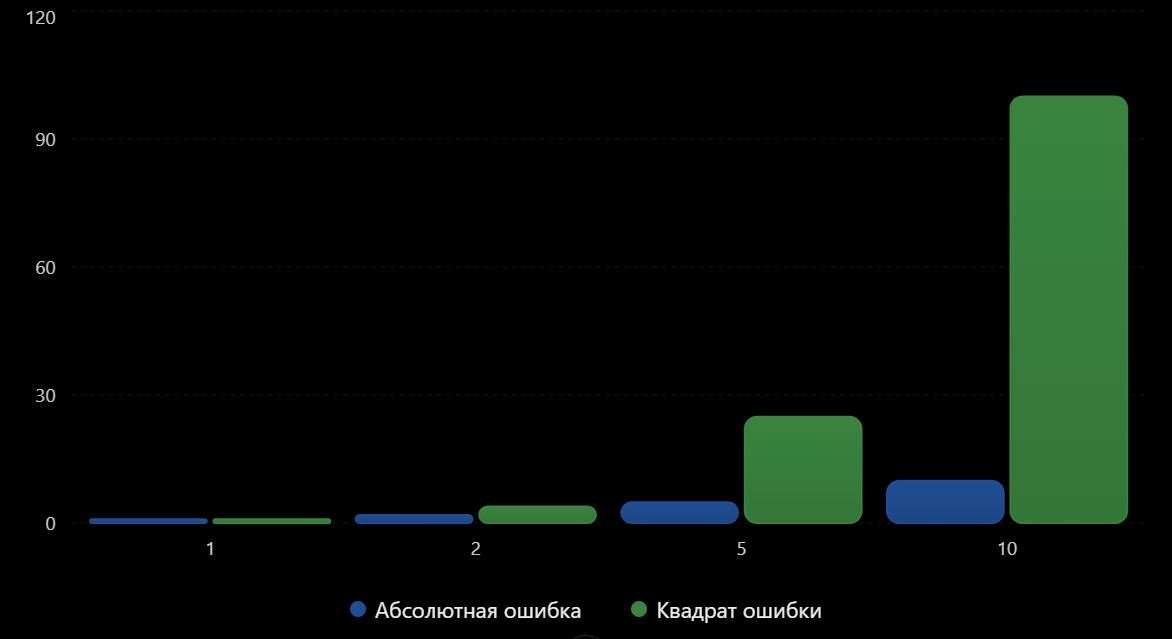

> Значения показаны для ошибки в условных единицах.

**Преимущества MSE**
- Сильно штрафует крупные ошибки, что полезно, когда особенно опасны большие промахи.
- Удобна для математической оптимизации: квадрат ошибки — гладкая функция, с которой удобно работать при обучении многих моделей.
- Позволяет выявлять модели, которые иногда предсказывают очень неточно.


**Недостатки MSE**
- Единицы измерения становятся квадратными. Если целевая переменная измеряется в кВт·ч, MSE измеряется в $(кВт·ч)^2$, что сложнее интерпретировать.
- Несколько крупных ошибок могут доминировать в общей оценке.
- MSE чувствительна к выбросам — объектам с необычно большими ошибками. Но сама по себе высокая ошибка не доказывает, что объект является выбросом: он может быть корректным и важным случаем.

**Когда использовать MSE**: когда крупные ошибки особенно нежелательны и необходимо сильнее штрафовать их, чем небольшие отклонения.



---



### RMSE — корень из средней квадратичной ошибки

RMSE — Root Mean Squared Error

$
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}
$

> RMSE — квадратный корень из MSE. Результат возвращается в исходные единицы целевой переменной.

RMSE сохраняет важную особенность MSE: крупные ошибки оказывают на итоговый результат повышенное влияние. При этом квадратный корень делает результат удобнее для интерпретации.

В предыдущем примере:

$
RMSE_A=\sqrt{4.4}\approx2.10
$

$
RMSE_B=\sqrt{20}\approx4.47
$

У второй модели RMSE больше, поскольку один промах на 10 единиц существенно ухудшает её качество по этой метрике.

Для первого примера с ошибками 10, 10, 20 и 10:

$
MSE=\frac{100+100+400+100}{4}=175
$

$
RMSE=\sqrt{175}\approx13.23
$


Если прогнозируемая величина измеряется в тысячах рублей, RMSE составит приблизительно 13,23 тысячи рублей.

**Как различать MAE и RMSE**
- MAE отвечает на вопрос: «Какова средняя абсолютная величина ошибки?»
- RMSE отвечает на вопрос: «Каков масштаб ошибки, если крупные отклонения получают дополнительный вес?»

RMSE не является буквально средней абсолютной ошибкой. Она может быть больше MAE, и для одной и той же выборки всегда выполняется:

$
RMSE\ge MAE
$

Равенство возможно, когда все абсолютные ошибки одинаковы.

---

### $R^2$ — коэффициент детерминации
В отличие от MAE, MSE и RMSE, коэффициент $R^2$ сравнивает модель с простым базовым прогнозом — обычно предсказанием среднего значения целевой переменной на обучающей выборке.

$
R^2=1-\frac{\sum_{i=1}^{n}(y_i-\hat y_i)^2}
{\sum_{i=1}^{n}(y_i-\bar y)^2}
$

Где:
- $\hat y_i$ — предсказание модели;
- $\bar y$ — среднее реальных значений на оцениваемой выборке;
- числитель — сумма квадратов ошибок модели;
- знаменатель — сумма квадратов отклонений реальных значений от их среднего.

Интуитивно $R^2$ сравнивает ошибки модели с тем, насколько различаются сами реальные значения вокруг среднего.

Как интерпретировать $R^2$

---
1.0

Идеальное совпадение
Все предсказания совпали с реальными значениями.

---

0.0

Не лучше базового среднего по сумме квадратов ошибок
На этой выборке модель не превзошла прогноз средним значением по данному критерию.

---

Меньше 0

Хуже базового прогноза
Сумма квадратов ошибок модели больше, чем у прогноза средним значением оцениваемой выборки.

---


Например, $R^2=0.80$ означает, что на оцениваемой выборке модель уменьшила сумму квадратов ошибок на 80% относительно базового прогноза средним значением. Это не означает, что 80% предсказаний правильные, и не гарантирует, что модель хорошо работает на новых данных.
У $R^2$ нет универсальной верхней границы качества вроде «0,7 — всегда хорошо». При оценке нужно учитывать предметную область, разброс целевой переменной и качество, необходимое для практического применения.

Преимущества $R^2$
- Не имеет единиц измерения.
- Позволяет оценить модель относительно простого базового подхода.
- Удобен для сравнения моделей на одной и той же выборке с одной и той же целевой переменной.

Недостатки $R^2$
- Не показывает типичную ошибку в исходных единицах.
- Может быть отрицательным на тестовой выборке.
- Сам по себе не доказывает причинную связь, отсутствие смещения или способность модели обобщать данные.
- Может быть неудобен для интерпретации, если реальные значения почти не различаются.

Если все реальные значения одинаковы, знаменатель формулы $R^2$ равен нулю, поэтому коэффициент математически не определён. В scikit-learn по умолчанию такие случаи обрабатываются специальным образом, чтобы результат часто оставался конечным; это поведение регулируется параметром force_finite.

## Как интерпретировать ошибки регрессии

**MAE** — средняя абсолютная разница между фактическим и предсказанным значением. Её удобно трактовать в единицах целевой переменной.

**MSE** — средний квадрат ошибки. Крупные ошибки сильнее влияют на эту метрику, поскольку разница возводится в квадрат.

**RMSE** — квадратный корень из MSE. Он возвращает оценку в исходный масштаб целевой переменной, сохраняя повышенную чувствительность к крупным ошибкам.

**R²** сравнивает качество прогноза с прогнозированием средним значением на той же выборке. Значение 1 соответствует идеальным предсказаниям; значение около 0 означает, что модель примерно не лучше такого базового подхода. На тестовых данных R² может быть отрицательным.

**Какую метрику выбрать?**
- Если важно объяснить заказчику среднюю ошибку в понятных единицах — MAE.
- Если большие промахи особенно опасны — MSE или RMSE.
- Если нужно оценить качество относительно простого базового прогноза — $R^2$.
- На практике полезно смотреть на несколько метрик одновременно: одна цифра редко описывает все свойства модели.

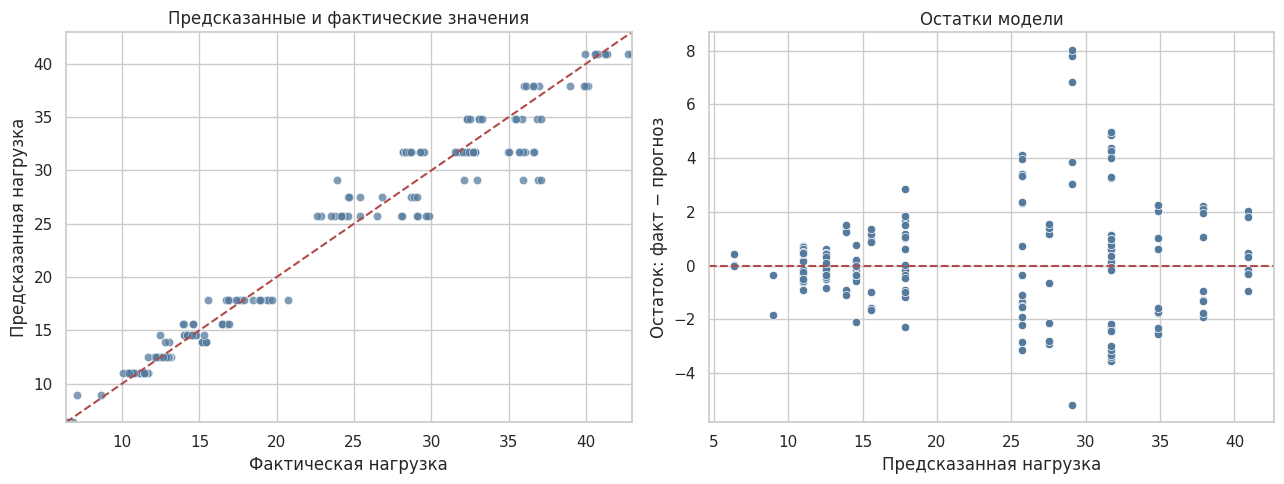

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test_e, pred_e, alpha=0.75, color="#547A9E", edgecolor="white", linewidth=0.4)
lims = [
    min(y_test_e.min(), pred_e.min()),
    max(y_test_e.max(), pred_e.max())
]
axes[0].plot(lims, lims, linestyle="--", color="#B14B4B", linewidth=1.5)
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set(title="Предсказанные и фактические значения", xlabel="Фактическая нагрузка", ylabel="Предсказанная нагрузка")

residuals = y_test_e.to_numpy() - pred_e
sns.scatterplot(x=pred_e, y=residuals, ax=axes[1], color="#547A9E")
axes[1].axhline(0, linestyle="--", color="#B14B4B", linewidth=1.5)
axes[1].set(title="Остатки модели", xlabel="Предсказанная нагрузка", ylabel="Остаток: факт − прогноз")

plt.tight_layout()
plt.show()

На первом графике точки, расположенные близко к диагонали, соответствуют удачным прогнозам. Систематическое отклонение от диагонали может указывать на области, где модель завышает или занижает нагрузку.

На графике остатков важно искать не только большие ошибки, но и структуру. Если ошибки образуют заметный рисунок, это может говорить о том, что модель не улавливает некоторую зависимость. Случайное расположение точек вокруг нуля — полезный признак, но не доказательство того, что модель полностью описывает процесс.

## Визуализация дерева регрессии

В отличие от линейной регрессии, дерево делит пространство признаков на области и выдаёт постоянный прогноз внутри каждого листа. Ограничение глубины помогает увидеть логику разбиений, не превращая рисунок в нечитаемую схему.

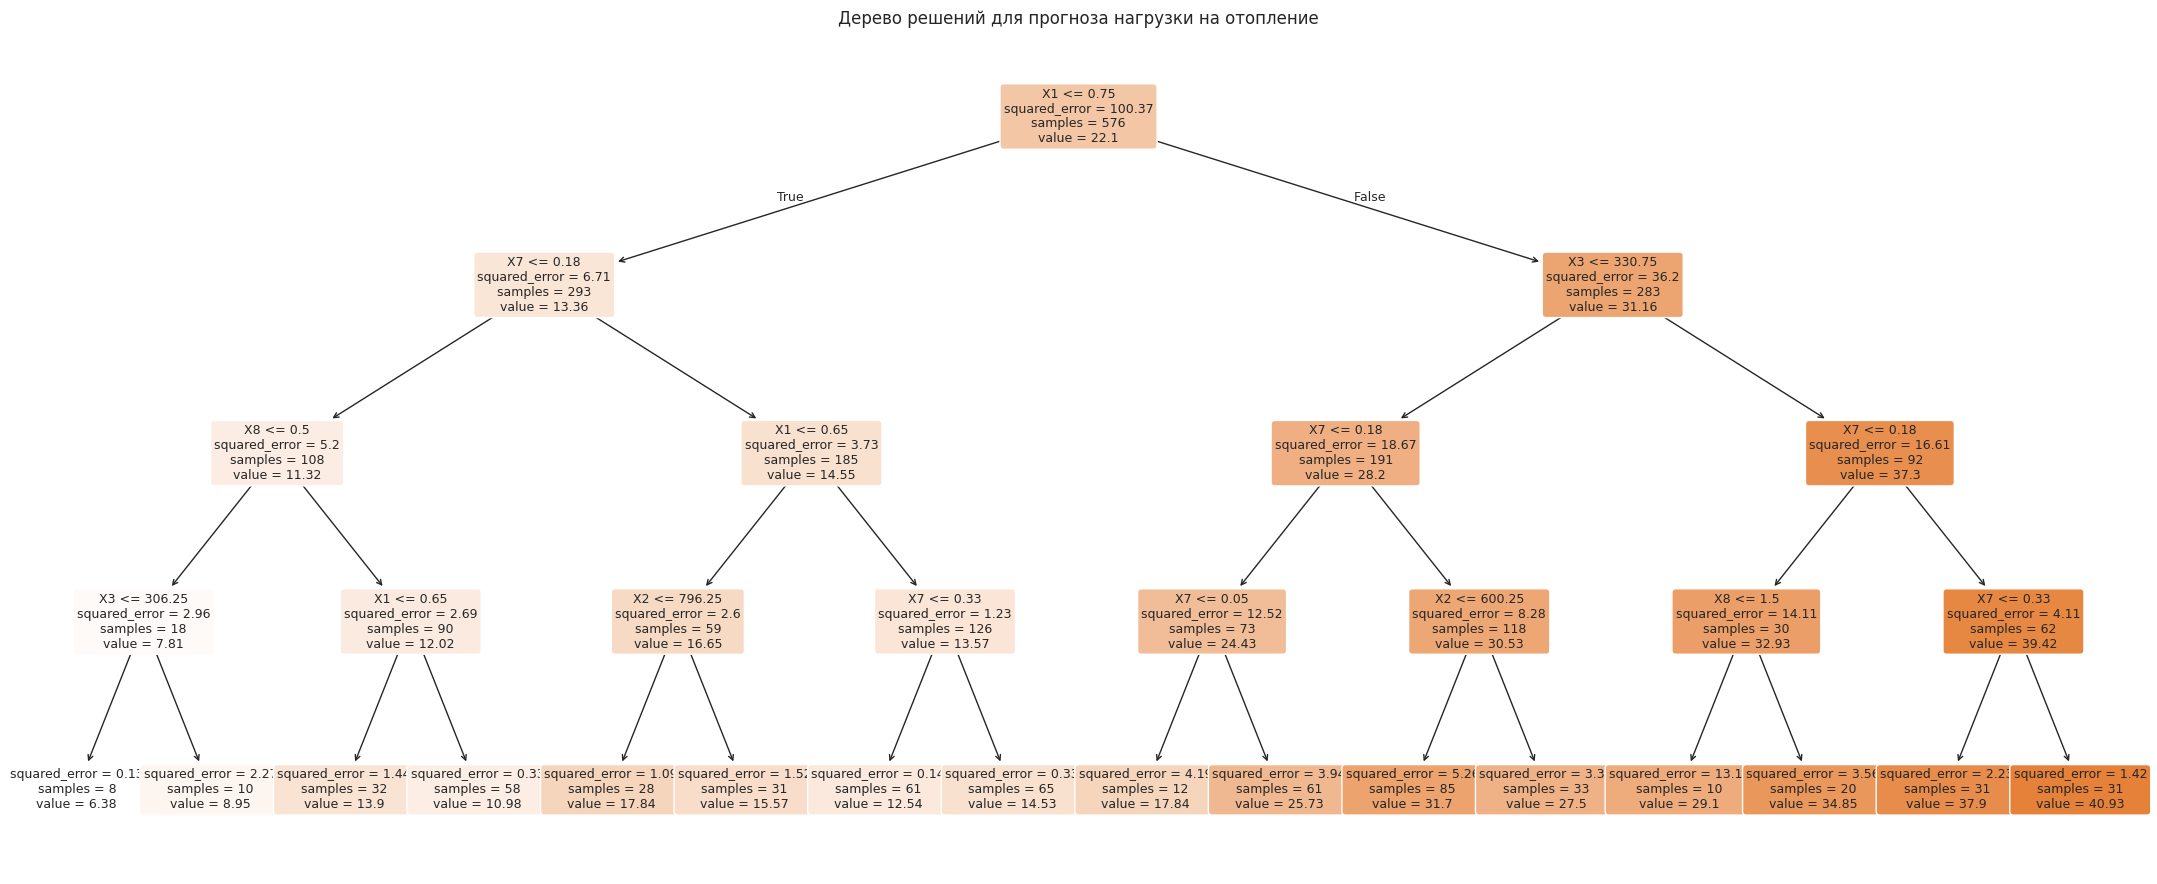

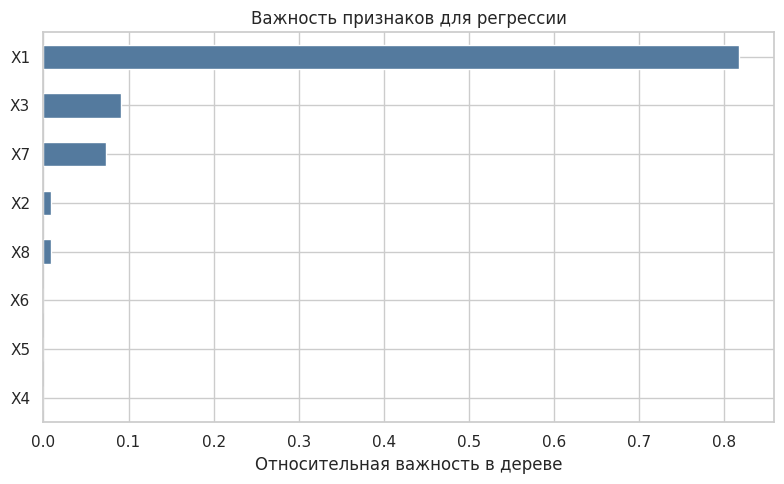

In [ ]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(
    tree_reg,
    feature_names=list(X_energy.columns),
    filled=True,
    rounded=True,
    impurity=True,
    precision=2,
    fontsize=9,
    ax=ax
)
ax.set_title("Дерево решений для прогноза нагрузки на отопление")
plt.tight_layout()
plt.show()

importance = pd.Series(tree_reg.feature_importances_, index=X_energy.columns).sort_values()
plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="#547A9E")
plt.xlabel("Относительная важность в дереве")
plt.title("Важность признаков для регрессии")
plt.tight_layout()
plt.show()

Важность признака показывает, насколько он участвовал в уменьшении ошибки внутри обученного дерева. Это не причинный эффект и не универсальный рейтинг признаков для любых моделей. При коррелирующих признаках важность может распределяться между ними, а при изменении обучающей выборки порядок способен поменяться.

## Сравнение классификации и регрессии

| Характеристика | Классификация: Bank Marketing | Регрессия: Energy Efficiency |
|---|---|---|
| Что предсказываем | Категорию `yes` / `no` | Числовую нагрузку на отопление |
| Тип целевой переменной | Категориальная | Непрерывная |
| Основные метрики | Accuracy, precision, recall, F1 | MAE, MSE, RMSE, R² |
| Важный вопрос | Какие ошибки классификации дороже? | Насколько велика ошибка в единицах прогноза? |
| Базовое сравнение | Частый класс | Среднее целевой переменной |

У дерева решений общий принцип одинаков: оно последовательно делит пространство признаков на области. Различается то, что хранится в листе и как измеряется качество. В классификации лист обычно связан с классом или распределением классов, а в регрессии — с числовым прогнозом.

## Итоги занятия

На примере банковской кампании мы увидели, почему одной accuracy недостаточно, если классы распределены неравномерно и цена ошибок различается. Матрица ошибок позволяет перейти от одной цифры к конкретным типам промахов.

На примере энергетической нагрузки мы оценили числовой прогноз несколькими метриками. MAE проще объяснить через среднюю величину ошибки, тогда как RMSE сильнее реагирует на отдельные крупные отклонения. Сравнение с базовой моделью показывает, есть ли у дерева практический выигрыш.

Наконец, обе модели требуют осторожной интерпретации. Результат зависит от разделения данных, параметров дерева, состава признаков и того, насколько учебная выборка похожа на будущие данные.

## Вопросы для самостоятельной работы

**Классификация**

- Постройте матрицу ошибок для базовой модели и сравните её с матрицей дерева.
- Измените `max_depth` и `min_samples_leaf`. Как меняются precision и recall для класса `yes`?
- Предположим, что контакт с клиентом дорогой. Какую метрику вы бы поставили в центр оценки и почему?
- Объясните своими словами, почему длительность разговора может привести к утечке информации в сценарии прогноза до звонка.

**Регрессия**

- Измените глубину дерева на 2 и 6. Сравните MAE и RMSE на тестовой выборке.
- В каком случае RMSE заметно выше MAE? Что это может сказать о распределении ошибок?
- Почему высокая важность признака не доказывает, что именно он вызывает изменение нагрузки?
- Что нужно проверить перед применением модели к зданию, геометрия которого существенно отличается от объектов в учебном наборе?

**Общий вопрос**

Можно ли назвать одну модель «лучше» другой, если одна решает задачу классификации, а другая — регрессии? Обоснуйте ответ через цель задачи и смысл метрик.